# Exercise: education and marijuana

In the lecture, the marginal effect was a prediction difference: predict on a grid, take differences. Today you use the same recipe on a new kind of model. The outcome is a yes/no answer: *should marijuana be legal?*

You do some steps yourself. Steps marked **AI step** you do with your AI assistant (opencode, in the terminal). For those:

1. Give your assistant a prompt. In step 3 you copy the prompt we wrote. In step 4 you write your own.
2. Your assistant adds the code to this notebook and runs it.
3. **Check the result.** Each AI step tells you what to look for.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ─────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## The data

`grass` asks: should marijuana be legal? 1 means yes, 2 means no, and `NA` means the question was not asked that year.

In tidymodels, a yes/no outcome must be a **factor**. We put `no` first so that `yes` is the event the model predicts.

In [3]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |>
    drop_na(educ, grass) |>
    mutate(grass = factor(grass, levels = c(2, 1), labels = c('no', 'yes')))

gss |> count(grass)

  grass n    
1 no    26198
2 yes   13243

## 1. Look at the data

Make `grass_by_educ`: the share of people who said yes at each education level. Then plot the share of people who said yes (y-axis) against educ (x-axis).

**This is for plotting only. The model will still be fit on every person.**

<details>
<summary>Hint</summary>

```R
# This will make the grass_by_educ table
grass_by_educ = gss |> group_by(educ) |> summarize(grass = sum(grass == 'yes') / n())
```
    
</details>

In [17]:
grass_by_educ <- gss |>
  group_by(educ) |>
  summarize(grass = sum(grass == "yes") / n())

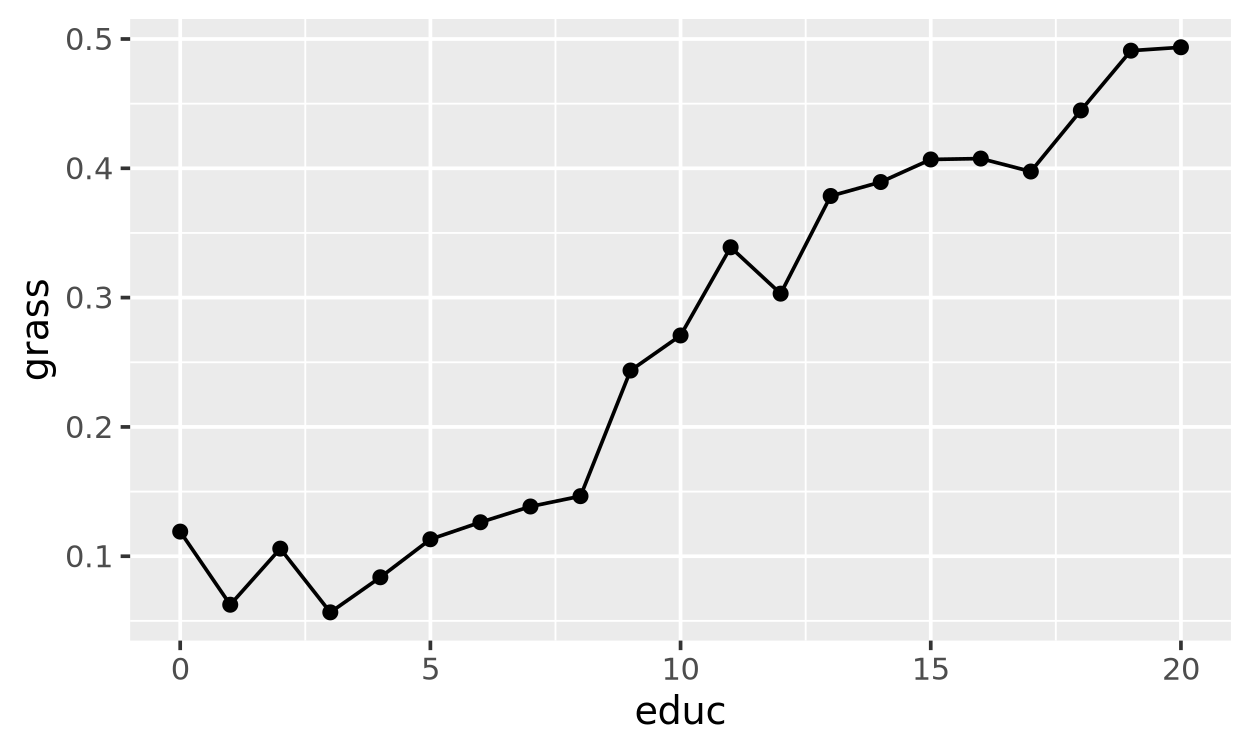

In [18]:
ggplot(grass_by_educ, aes(x = educ, y = grass)) +
  geom_point() +
  geom_line()

## 2. Fit a logistic regression model

For a yes/no outcome we use **logistic regression**. It predicts the **probability** of yes. Because we are using TidyModels the code will resemble what we wrote for `linear_reg()`.

In [14]:
fit_logit <- logistic_reg() |> fit(grass ~ educ, data = gss)

fit_logit

parsnip model object


Call:  stats::glm(formula = grass ~ educ, family = stats::binomial, 
    data = data)

Coefficients:
(Intercept)         educ  
    -2.2830       0.1223  

Degrees of Freedom: 39440 Total (i.e. Null);  39439 Residual
Null Deviance:	    50340 
Residual Deviance: 49140 	AIC: 49140

The model is:

$$ \log\left(\frac{p}{1 - p}\right) = a_1 + a_2 \times \text{educ} $$

$p$ is the probability of yes. The left side is called the **log odds**.

This is a straight line, but on the log-odds scale. That is like log income in the lecture, which was a straight line on the log scale. So the slope (about 0.12) is in log odds. It is **not** a change in probability.

## 3. AI step: plot the model

Open a terminal and run `opencode`. Your assistant has tools to add, edit, and run cells in this notebook.

**Copy this prompt into opencode:**

```text
I am working in exercises/10-marginal-effect-exercise.ipynb, with R and tidymodels.
I already ran the cells that make these objects:

- fit_logit: a tidymodels logistic_reg() model, fit with grass ~ educ.
  grass is a factor with levels "no" and "yes".
- grass_by_educ: a table with two columns, educ and grass.
  grass is the share of people who said yes at each education level.

Put R code in the empty code cell in step 3 that:

1. Makes a grid with educ = 0:20.
2. Predicts on the grid with fit_logit and type = 'prob', and binds the grid to the predictions.
3. Plots the grass_by_educ points with educ on the x-axis, and draws .pred_yes as a line on top.

Then run the cell. Use tidymodels only. Do not load other packages.
Do not change any other cells.
```

**Your assistant puts its code in the cell below and runs it.**

Read the code. If the cell shows an error, ask your assistant to fix it.

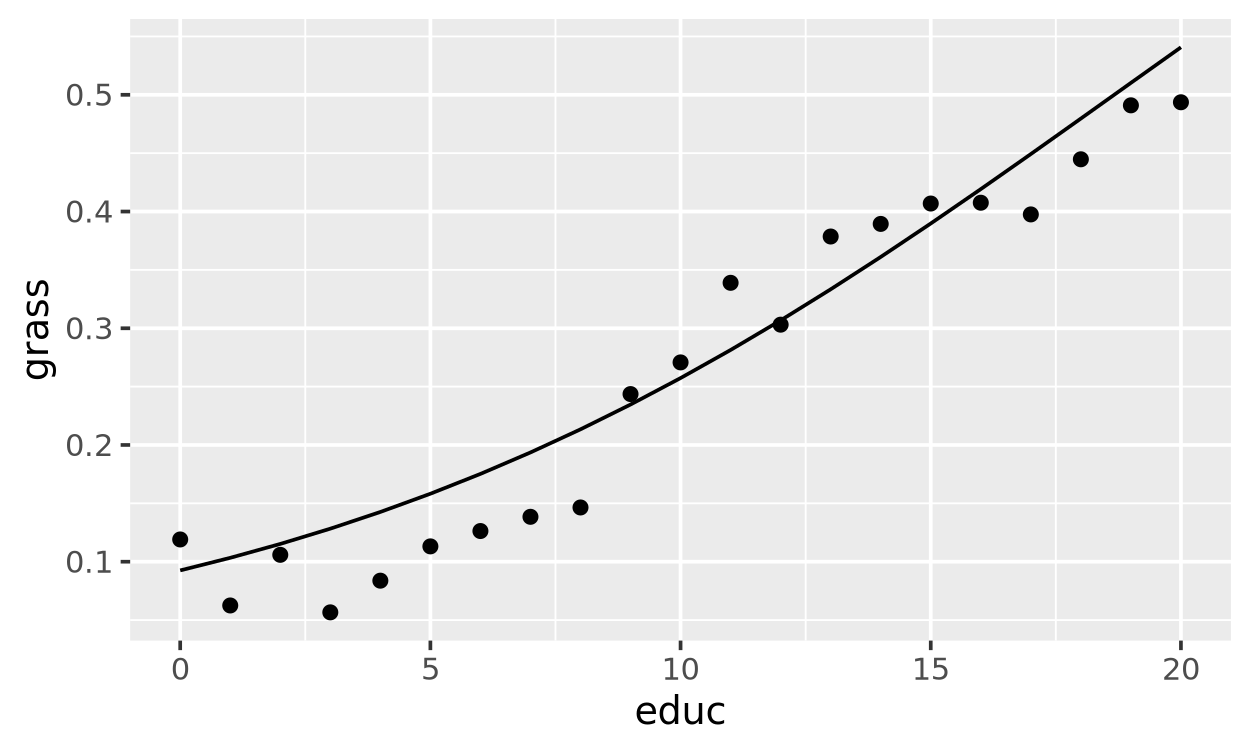

In [15]:
grid <- tibble(educ = 0:20)

preds <- predict(fit_logit, new_data = grid, type = 'prob') |>
    bind_cols(grid)

ggplot(grass_by_educ, aes(x = educ, y = grass)) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred_yes))

**Check:** the curve should go from about 0.09 at 0 years to about 0.54 at 20 years.

Is it a straight line?

## 4. AI step: the average marginal effect

The marginal effect depends on where you are. But sometimes you want **one number**. The **average marginal effect** (AME) is one way to get it:

1. For each person, predict the probability of yes at their own `educ`.
2. Predict again at `educ + 1`.
3. Subtract to find the change in attitude toward marijuana with one additional education year and take the mean of this value over all people.

Write a prompt that asks your assistant to compute the AME of `educ` with `fit_logit` and `gss`. Spell out the three steps. Tell it to use tidymodels only.

**Put your prompt below in a markdown cell and then run it in OpenCode:** 

In [16]:
preds_orig <- predict(fit_logit, new_data = gss, type = 'prob')

preds_plus1 <- predict(fit_logit, new_data = gss |> mutate(educ = educ + 1), type = 'prob')

ame <- mean(preds_plus1$.pred_yes - preds_orig$.pred_yes)

ame

[1] 0.02694028

**Check:** you should get about 0.027.

Read the code too. Does it use `type = 'prob'`? Does it add 1 to `educ` for every person? If either is missing, the number is wrong, even if it looks OK.